# Практическая работа № 4 — интерполяция SSH brute-force инцидентов

**Исходные данные:** первые 60 точек из файла «Ермакова 1», 03.09.2026, период наблюдения 30 секунд.

**Задание:** изучить четыре способа полиномиальной интерполяции — канонический, Лагранжа, Ньютона, Эйткена — на двух временных интервалах, не менее трёх раз изменяя степень; построить графики, вывести коэффициенты и оценить ошибки.

**Математическое уточнение:** интерполяционный многочлен по 60 различным узлам имеет степень **не выше 59**. При использовании всех 60 узлов его значения в этих узлах совпадут с исходными (MAE≈0), но **это не проверка прогностической способности**. Если при уменьшении степени использовать все 60 точек, то это уже **аппроксимация МНК**, а не точная интерполяция. Здесь при меньшей степени выбирается `степень+1` узлов, остальные фактические точки используются для оценки реконструкции.

Два заданных интервала: **1–30 и 31–60**. Для честной проверки прогноза в каждом из них первые 24 точки используются для построения полиномов, а последние 6 — только для проверки (1–24 → 25–30 и 31–54 → 55–60). Это экстраполяция, отдельно от интерполяции. Методы при одинаковых узлах математически дают **один и тот же полином**; сравнивать целесообразность нужно прежде всего между **степенями**, а не по расхождению ошибок четырёх эквивалентных записей.

Для степени 59 используется высокая точность `mpmath` и нормировка аргумента, поскольку обычная арифметика `float64` и матрица Вандермонда могут дать большие численные ошибки. Полином высокой степени на равноотстоящих зашумлённых данных способен сильно колебаться между узлами (эффект Рунге).

In [1]:
import sys, subprocess, importlib.util
for package in ("mpmath", "numpy", "pandas", "matplotlib"):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mpmath as mp
from IPython.display import display
from itertools import combinations

mp.mp.dps = 90
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Число точек: 60 | Минимум: 16.0 | Максимум: 27.0 | Среднее: 21.833


,Номер,Число инцидентов
0,1,21
1,2,18
2,3,21
3,4,18
4,5,18
5,6,22
6,7,16
7,8,27
8,9,26
9,10,22


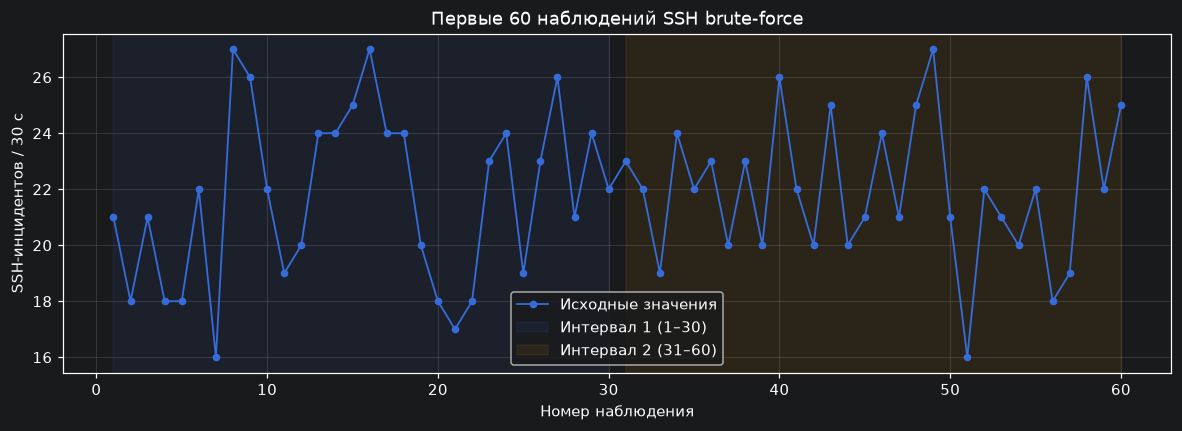

In [6]:
# Все 60 значений извлечены из исходной таблицы; отдельный файл загружать не нужно.
y = np.array([21, 18, 21, 18, 18, 22, 16, 27, 26, 22, 19, 20, 24, 24, 25, 27, 24, 24, 20, 18, 17, 18, 23, 24, 19, 23, 26, 21, 24, 22, 23, 22, 19, 24, 22, 23, 20, 23, 20, 26, 22, 20, 25, 20, 21, 24, 21, 25, 27, 21, 16, 22, 21, 20, 22, 18, 19, 26, 22, 25], dtype=float)
t = np.arange(1, 61, dtype=int)
assert len(y) == 60 and y[0] == 21 and y[-1] == 25
print('Число точек:', len(y), '| Минимум:', y.min(), '| Максимум:', y.max(), '| Среднее:', round(y.mean(), 3))
display(pd.DataFrame({'Номер':t, 'Число инцидентов':y.astype(int)}).head(10))
plt.figure(figsize=(13,4)); plt.plot(t,y,'o-',lw=1.2,ms=4,label='Исходные значения')
plt.axvspan(1,30,alpha=.08,color='royalblue',label='Интервал 1 (1–30)')
plt.axvspan(31,60,alpha=.08,color='orange',label='Интервал 2 (31–60)')
plt.xlabel('Номер наблюдения'); plt.ylabel('SSH-инцидентов / 30 с')
plt.title('Первые 60 наблюдений SSH brute-force'); plt.legend(); plt.show()

## 1. Четыре алгоритма для одного интерполяционного полинома

Пусть выбрано `n+1` узлов `(x_i, y_i)`. Интерполирующий многочлен степени не выше `n` удовлетворяет `P(x_i)=y_i`.

- **Канонический:** `P(u)=a₀+a₁u+…+aₙuⁿ`. Коэффициенты `a` находим решением системы Вандермонда.
- **Лагранж:** `L(u)=Σ yᵢ ∏_{j≠i}(u−uⱼ)/(uᵢ−uⱼ)`. Для устойчивого вычисления используется математически эквивалентная барицентрическая форма.
- **Ньютон:** `N(u)=c₀+c₁(u−u₀)+c₂(u−u₀)(u−u₁)+…` с разделёнными разностями `cᵢ`.
- **Эйткен (Невилл):** рекурсивная интерполяционная схема по значениям в узлах; ее итог также совпадает с тем же `P(u)`.

**Нормировка:** `u=(t−center)/scale`. Выводимые коэффициенты относятся именно к переменной **u**, а не непосредственно к `t`.

In [7]:
METHODS = ['Канонический', 'Лагранж', 'Ньютон', 'Эйткен']

def make_nodes(x, values, degree):
    """Равномерно распределенные узлы, не более degree+1; без МНК."""
    x, values = np.asarray(x), np.asarray(values)
    assert len(x) == len(values) and degree < len(x) and degree >= 1
    indices = np.rint(np.linspace(0, len(x)-1, degree+1)).astype(int)
    assert len(np.unique(indices)) == degree+1
    return x[indices], values[indices], indices

def build_poly(xnodes, ynodes):
    """Единый набор полиномиальных коэффициентов для 4 эквивалентных реализаций."""
    xnodes, ynodes = list(xnodes), list(ynodes)
    nn=len(xnodes)
    xx=[mp.mpf(int(x)) for x in xnodes]
    yy=[mp.mpf(str(float(y))) for y in ynodes]
    center=(xx[0]+xx[-1])/2
    scale=(xx[-1]-xx[0])/2
    assert scale>0
    uu=[(x-center)/scale for x in xx]
    # 1. Канонический полином: Вандермонд и СЛАУ
    V=mp.matrix([[u**j for j in range(nn)] for u in uu])
    coef=list(mp.lu_solve(V, mp.matrix(yy)))
    # 2. Барицентрические веса Лагранжа
    ww=[1/mp.fprod(uu[i]-uu[j] for j in range(nn) if j!=i) for i in range(nn)]
    # 3. Разделенные разности Ньютона
    dd=yy.copy()
    newt=[dd[0]]
    for k in range(1,nn):
        dd=[(dd[j+1]-dd[j])/(uu[j+k]-uu[j]) for j in range(nn-k)]
        newt.append(dd[0])
    return {'x':xx, 'y':yy, 'u':uu, 'center':center, 'scale':scale,
            'canonical':coef, 'weights':ww, 'newton':newt, 'degree':nn-1}

def eval_one(poly, t_query, method):
    u=(mp.mpf(str(t_query))-poly['center'])/poly['scale']
    nodes, yy = poly['u'], poly['y']
    n=len(nodes)
    for k in range(n):
        if u==nodes[k]: return yy[k]
    if method=='Канонический':
        result=mp.mpf('0')
        for a in reversed(poly['canonical']): result=result*u+a
        return result
    if method=='Лагранж':
        ratios=[poly['weights'][i]/(u-nodes[i]) for i in range(n)]
        return mp.fsum(ratios[i]*yy[i] for i in range(n))/mp.fsum(ratios)
    if method=='Ньютон':
        result=poly['newton'][-1]
        for j in range(n-2,-1,-1): result=poly['newton'][j]+(u-nodes[j])*result
        return result
    if method=='Эйткен':
        # Схема Невилла—Эйткена, устойчивее прямого полинома на небольших n
        q=yy.copy()
        for width in range(1,n):
            for i in range(n-width):
                j=i+width
                q[i]=((u-nodes[i])*q[i+1]-(u-nodes[j])*q[i])/(nodes[j]-nodes[i])
        return q[0]
    raise ValueError('Неизвестный метод')

def predict(poly, xnew, method):
    xnew=np.atleast_1d(np.asarray(xnew))
    return np.array([float(eval_one(poly, float(z), method)) for z in xnew])

def metrics(true, predicted):
    true=np.asarray(true, dtype=float); predicted=np.asarray(predicted,dtype=float)
    dif=true-predicted
    return {'MAE': float(np.mean(np.abs(dif))),
            'MSE': float(np.mean(dif**2)),
            'RMSE':float(np.sqrt(np.mean(dif**2))),
            'MAPE, %':float(np.mean(np.abs(dif)/true)*100)}

def print_equation(poly, max_terms=16):
    """Коэффициенты всегда можно получить все, независимо от степени."""
    aa=poly['canonical']; n=len(aa)-1
    print(f"P(u) = a0 + a1*u + ... + a{n}*u^{n}")
    print(f"u = (t - {mp.nstr(poly['center'],8)}) / {mp.nstr(poly['scale'],8)}")
    tbl=pd.DataFrame({'Степень u':range(n+1), 'Канонический коэффициент a_k': [mp.nstr(c,12) for c in aa],
                      'Коэффициент разделенных разностей Ньютона c_k':[mp.nstr(c,12) for c in poly['newton']]})
    if max_terms is None or n+1<=max_terms:
        display(tbl)
    else:
        display(pd.concat([tbl.head(max_terms//2), tbl.tail(max_terms//2)]))
        print(f"Отображены крайние {max_terms} строк; полный набор — poly['canonical'], poly['newton']")
    return tbl

# Контроль: линейный полином должен совпадать для всех четырех форм.
p0=build_poly([1,5], [21,18]); x0=3.5
print('Проверка четырех реализаций:', {m:mp.nstr(eval_one(p0,x0,m),12) for m in METHODS})

Проверка четырех реализаций: {'Канонический': '19.125', 'Лагранж': '19.125', 'Ньютон': '19.125', 'Эйткен': '19.125'}


## 2. Один интерполяционный полином через все 60 точек

Это **степень 59**, а не 60. Четыре способа дадут одну кривую. Чтобы увидеть опасность полинома высокой степени, изображаются и фактические узлы, и значения между ними. На отдельном графике ось Y ограничена для удобства чтения; реальная амплитуда колебаний между узлами выводится числом.

In [8]:
full = build_poly(t,y)
print('Степень:', full['degree'], '| узлов:', len(t))
# Проверим узлы и совпадение четырех способов в одной НЕузловой точке
for method in METHODS:
    errors = [abs(eval_one(full, float(q), method) - mp.mpf(str(float(v)))) for q,v in zip(t,y)]
    print(f'{method:16s} | максимальная ошибка В УЗЛАХ:', mp.nstr(max(errors),8))
print('Значение в промежуточной точке t=27.5:', {m:mp.nstr(eval_one(full,27.5,m),9) for m in METHODS})
coeffs_59 = print_equation(full, max_terms=14)
# При желании можно распечатать ВСЕ коэффициенты следующей строкой:
# display(coeffs_59)

Степень: 59 | узлов: 60
Канонический     | максимальная ошибка В УЗЛАХ: 0.0
Лагранж          | максимальная ошибка В УЗЛАХ: 0.0
Ньютон           | максимальная ошибка В УЗЛАХ: 0.0
Эйткен           | максимальная ошибка В УЗЛАХ: 0.0
Значение в промежуточной точке t=27.5: {'Канонический': '22.9069212', 'Лагранж': '22.9069212', 'Ньютон': '22.9069212', 'Эйткен': '22.9069212'}
P(u) = a0 + a1*u + ... + a59*u^59
u = (t - 30.5) / 29.5


,Степень u,Канонический коэффициент a_k,Коэффициент разделенных разностей Ньютона c_k
0,0,21.5079174969,21.0
1,1,42.6576173997,-88.5
2,2,4063.38737829,2610.75
3,3,-49592.8630313,-51344.75
4,4,-2249180.40021,662668.179687
5,5,13702008.9164,-5399167.88307
6,6,451643337.321,20138275.6099
53,53,-1.66348641576e+25,-4.27111609254e+23
54,54,9.36172684511e+24,4.45123528345e+23
55,55,5.63068270586e+24,-4.20605053043e+23


Отображены крайние 14 строк; полный набор — poly['canonical'], poly['newton']


Максимальное |P(t)| МЕЖДУ УЗЛАМИ (каноническая форма): 2.311e+14


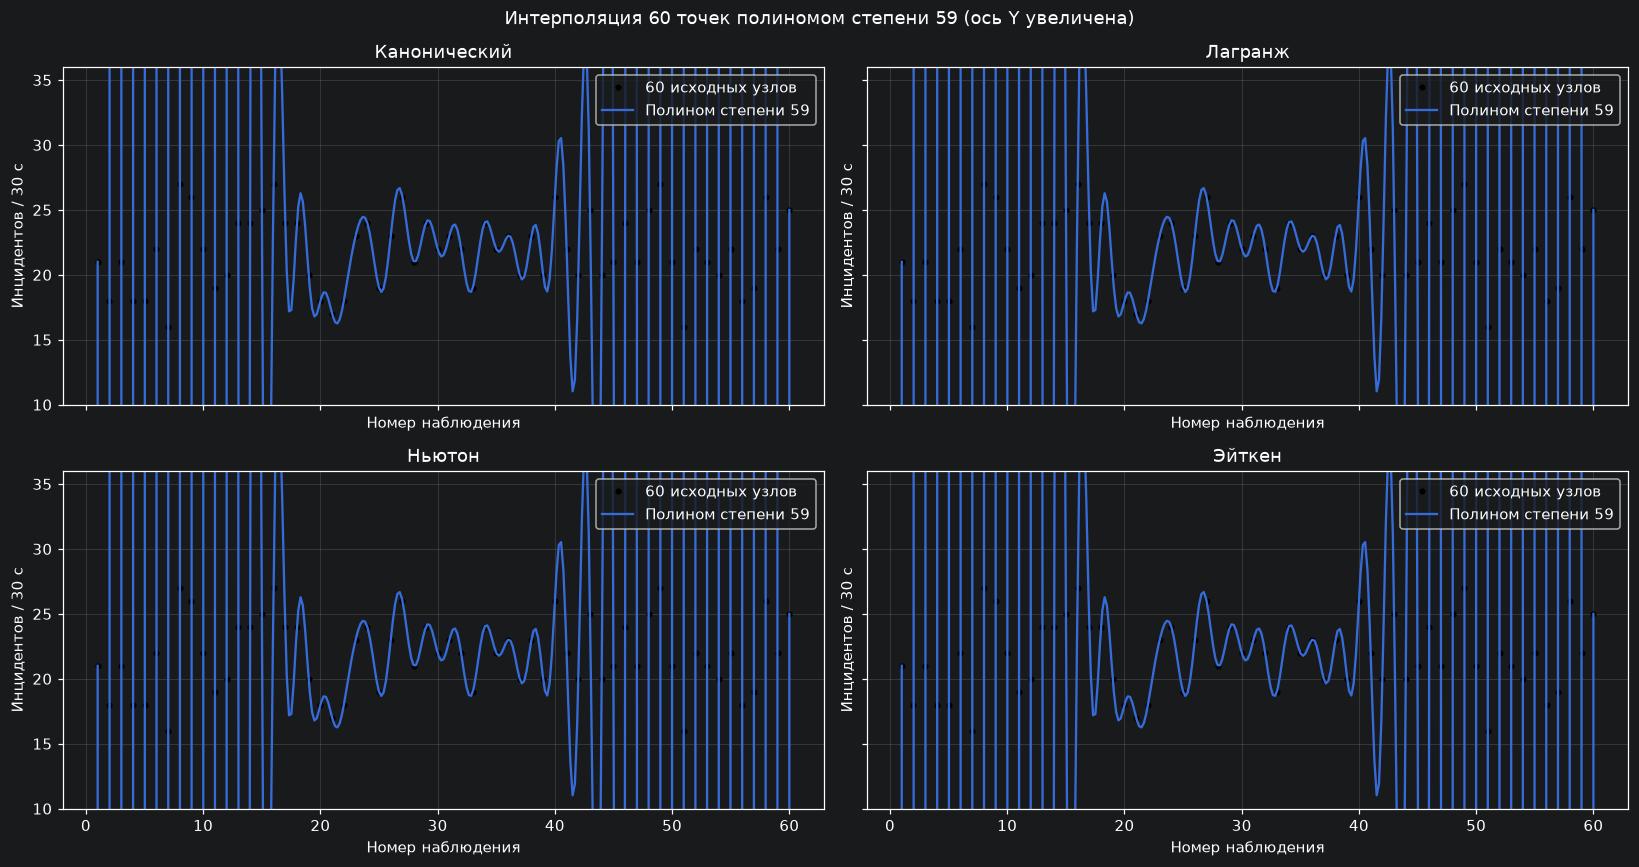

ВАЖНО: график ограничен по вертикали, полином выходит за эти пределы.


In [9]:
grid=np.linspace(1,60,301)
curves={m: predict(full,grid,m) for m in METHODS}
print('Максимальное |P(t)| МЕЖДУ УЗЛАМИ (каноническая форма):', f'{np.max(np.abs(curves["Канонический"])):.4g}')
fig,axs=plt.subplots(2,2,figsize=(15,8),sharex=True,sharey=True)
for ax,m in zip(axs.flat,METHODS):
    ax.plot(t,y,'ko',ms=3,label='60 исходных узлов')
    ax.plot(grid,curves[m],lw=1.5,label='Полином степени 59')
    ax.set_ylim(10,36) # Только графический масштаб: экстремумы не удалены из расчета
    ax.set_title(m); ax.set_xlabel('Номер наблюдения'); ax.set_ylabel('Инцидентов / 30 с')
    ax.legend(loc='upper right')
fig.suptitle('Интерполяция 60 точек полиномом степени 59 (ось Y увеличена)')
plt.tight_layout(); plt.show()
print('ВАЖНО: график ограничен по вертикали, полином выходит за эти пределы.')

## 3. Два временных интервала: изменение степени 4 раза

Для интервала **1–30** и интервала **31–60** строим полиномы степеней **29, 14, 7, 3, 1**. Полином степени 29 проходит через все 30 точек. Для меньших степеней берём равномерно распределённые `n+1` узлов **из того же интервала**, а остальные точки служат проверкой восстановления. MAE на узлах заведомо около нуля и не служит критерием выбора.

**Важно:** MAE на пропущенных точках показывает качество *интерполяции внутри интервала*, а не прогноза за его пределами.

In [10]:
INTERVALS=[(1,30),(31,60)]
DEGREES_FULL=[29,14,7,3,1]
reconstruction_rows=[]
polys_intervals={}
for start,end in INTERVALS:
    xint=t[start-1:end]; yint=y[start-1:end]
    label=f'{start}–{end}'
    for deg in DEGREES_FULL:
        xn,yn,idx=make_nodes(xint,yint,deg)
        p=build_poly(xn,yn)
        polys_intervals[(label,deg)] = (p,idx)
        missed=np.setdiff1d(np.arange(len(xint)),idx)
        for m in METHODS:
            if len(missed)>0:
                met=metrics(yint[missed],predict(p,xint[missed],m))
            else:
                met={'MAE': np.nan, 'MSE':np.nan, 'RMSE':np.nan,'MAPE, %':np.nan}
            reconstruction_rows.append({'Интервал':label,'Степень':deg,'Метод':m,
                                        'Узлов':len(idx),'Проверочных точек':len(missed),**met})
results_reconstruct=pd.DataFrame(reconstruction_rows)
print('Ошибки НА ТОЧКАХ, НЕ ВХОДЯЩИХ В УЗЛЫ (пусто для полинома степени 29):')
display(results_reconstruct.query('Метод=="Канонический"').round(4))
print('Формы Лагранжа, Ньютона и Эйткена дают те же метрики, так как полином единственный.')

Ошибки НА ТОЧКАХ, НЕ ВХОДЯЩИХ В УЗЛЫ (пусто для полинома степени 29):


,Интервал,Степень,Метод,Узлов,Проверочных точек,MAE,MSE,RMSE,"MAPE, %"
0,1–30,29,Канонический,30,0,NaN,NaN,NaN,NaN
4,1–30,14,Канонический,15,15,20.4309,2433.2297,49.3278,104.9775
8,1–30,7,Канонический,8,22,4.1932,28.7056,5.3578,20.6571
12,1–30,3,Канонический,4,26,3.7052,19.7051,4.4390,16.0144
16,1–30,1,Канонический,2,28,2.7660,9.8818,3.1435,13.0671
20,31–60,29,Канонический,30,0,NaN,NaN,NaN,NaN
24,31–60,14,Канонический,15,15,16.1938,1041.0940,32.2660,74.4385
28,31–60,7,Канонический,8,22,3.4230,17.3056,4.1600,16.0954
32,31–60,3,Канонический,4,26,2.2060,7.6716,2.7698,10.3542
36,31–60,1,Канонический,2,28,2.8264,11.6909,3.4192,14.0390


Формы Лагранжа, Ньютона и Эйткена дают те же метрики, так как полином единственный.


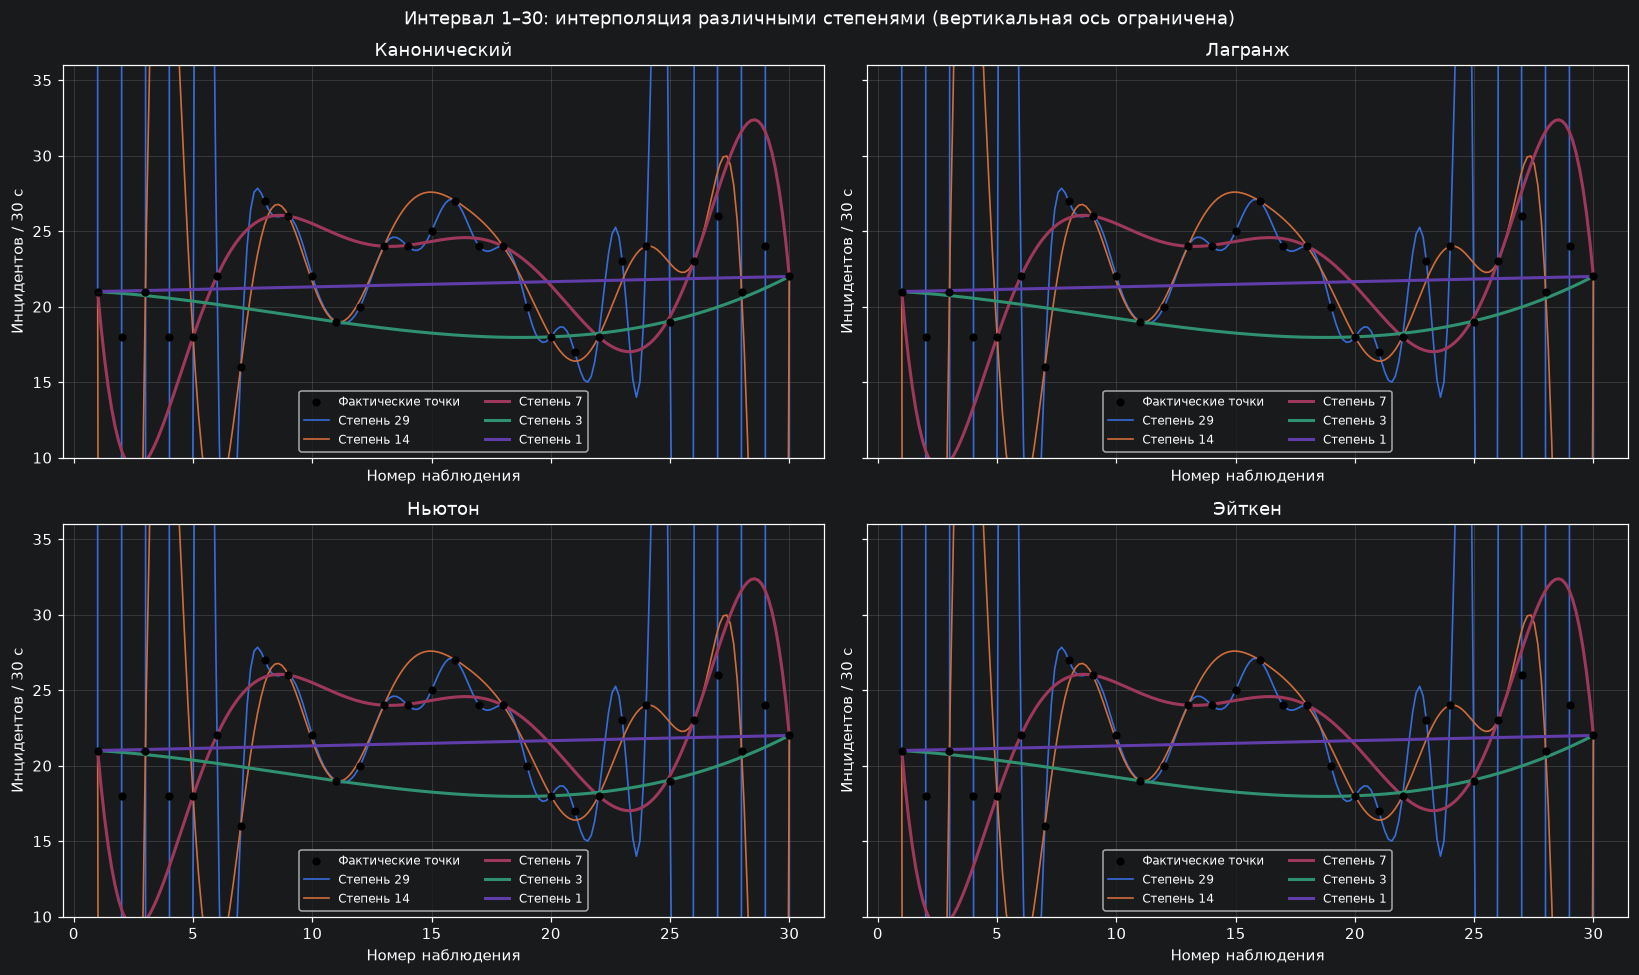

Интервал 1–30: канонические коэффициенты для n=3 и n=7 (в нормированной переменной u)
  Степень 3:
P(u) = a0 + a1*u + ... + a3*u^3
u = (t - 15.5) / 14.5


,Степень u,Канонический коэффициент a_k,Коэффициент разделенных разностей Ньютона c_k
0,0,18.1802631579,21.0
1,1,-1.83611111111,-2.9
2,2,3.31973684211,0.983625730994
3,3,2.33611111111,2.33611111111


  Степень 7:
P(u) = a0 + a1*u + ... + a7*u^7
u = (t - 15.5) / 14.5


,Степень u,Канонический коэффициент a_k,Коэффициент разделенных разностей Ньютона c_k
0,0,24.4510043275,21.0
1,1,3.41010356592,-10.875
2,2,-15.723961835,72.2734375
3,3,-125.444143156,-166.721679687
4,4,18.752974368,215.823327864
5,5,368.20147643,-230.544755871
6,6,-5.98001686054,239.68741998
7,7,-245.667436841,-245.667436841


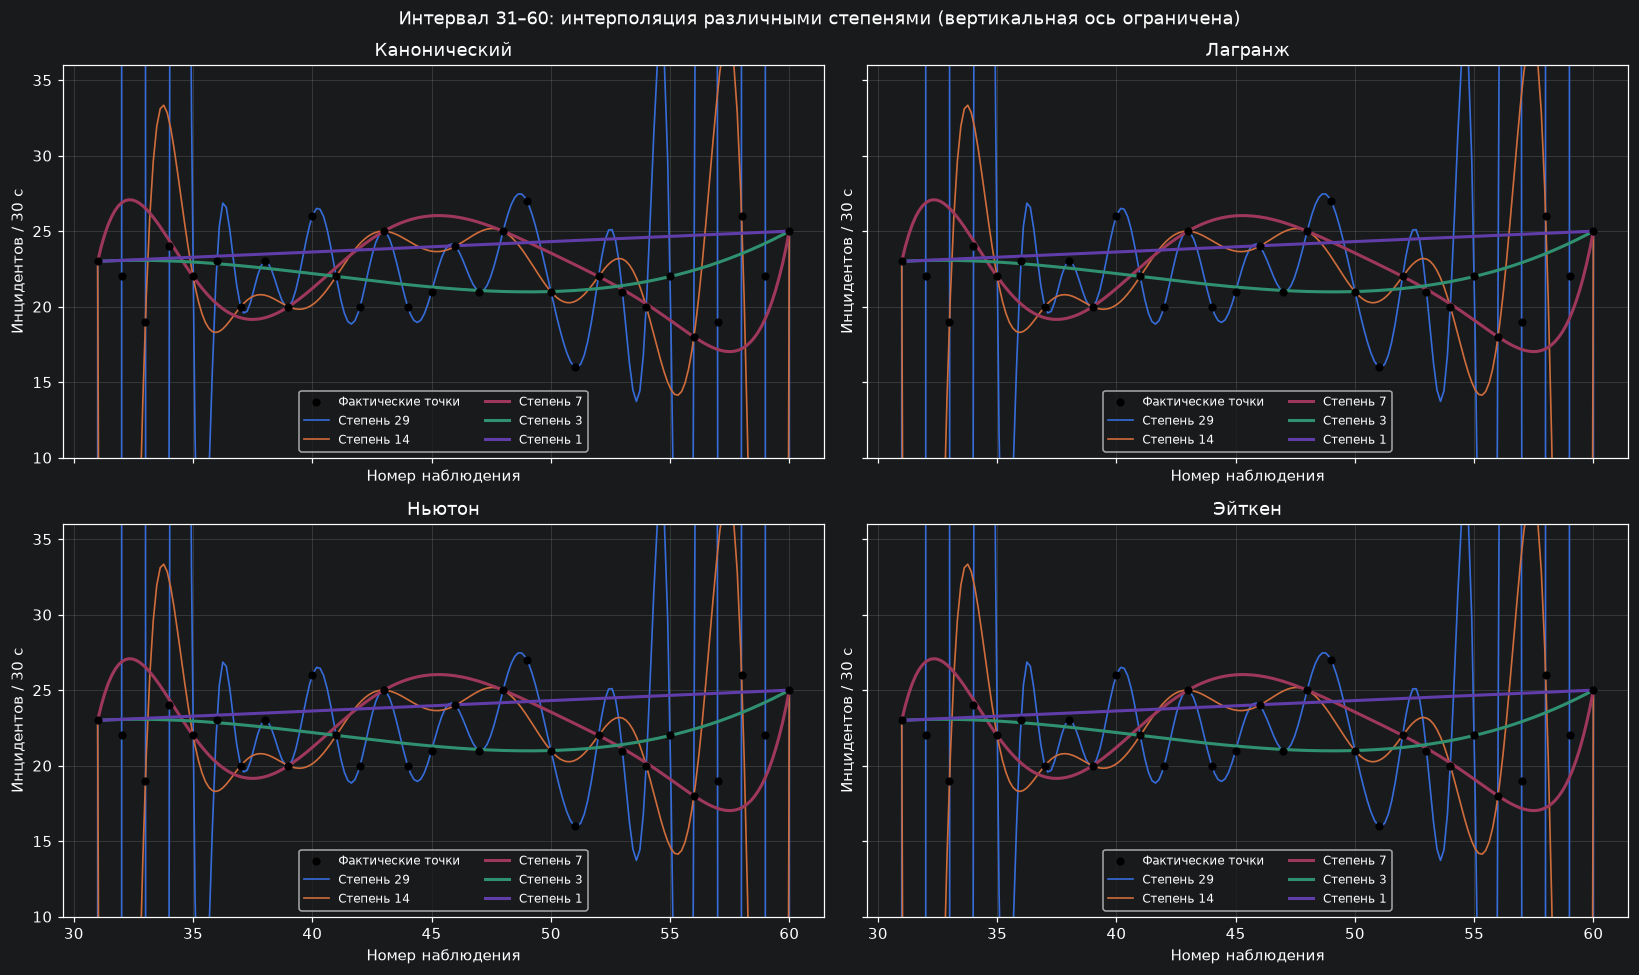

Интервал 31–60: канонические коэффициенты для n=3 и n=7 (в нормированной переменной u)
  Степень 3:
P(u) = a0 + a1*u + ... + a3*u^3
u = (t - 45.5) / 14.5


,Степень u,Канонический коэффициент a_k,Коэффициент разделенных разностей Ньютона c_k
0,0,21.2335526316,23.0
1,1,-1.8894005848,-1.45
2,2,2.76644736842,-0.122953216374
3,3,2.8894005848,2.8894005848


  Степень 7:
P(u) = a0 + a1*u + ... + a7*u^7
u = (t - 45.5) / 14.5


,Степень u,Канонический коэффициент a_k,Коэффициент разделенных разностей Ньютона c_k
0,0,26.0250411688,23.0
1,1,-1.01114950938,-3.625
2,2,-36.2912008848,-6.5703125
3,3,37.6537896154,63.5130208333
4,4,61.6629811468,-125.708841008
5,5,-125.064752695,143.865682291
6,6,-27.3968214309,-116.81893402
7,7,89.4221125891,89.4221125891


In [11]:
# Отдельный график для каждого интервала со степенями; все 4 метода представлены панелями.
for start,end in INTERVALS:
    label=f'{start}–{end}'
    xx=t[start-1:end]; yy=y[start-1:end]
    fine=np.linspace(start,end,200)
    fig, axs = plt.subplots(2,2,figsize=(15,9),sharex=True,sharey=True)
    for ax,m in zip(axs.flat,METHODS):
        ax.scatter(xx,yy,c='k',s=19,label='Фактические точки',zorder=5)
        for deg in DEGREES_FULL:
            p,idx=polys_intervals[(label,deg)]
            curve=predict(p,fine,m)
            ax.plot(fine,curve,lw=1.1 if deg>10 else 2,label=f'Степень {deg}')
        ax.set_ylim(10,36) # Для обозримости высоких степеней
        ax.set_title(m); ax.set_xlabel('Номер наблюдения'); ax.set_ylabel('Инцидентов / 30 с')
        ax.legend(fontsize=8,ncol=2)
    fig.suptitle(f'Интервал {label}: интерполяция различными степенями (вертикальная ось ограничена)')
    fig.tight_layout(); plt.show()
    print(f'Интервал {label}: канонические коэффициенты для n=3 и n=7 (в нормированной переменной u)')
    for deg in [3,7]:
        print(f'  Степень {deg}:')
        print_equation(polys_intervals[(label,deg)][0],max_terms=None)

## 4. Прогностическая проверка без подсматривания в будущее

Из каждого интервала длиной 30 наблюдений **первые 24 известны**, **последние 6 скрыты на этапе построения**. Полином строится из `n+1` узлов в первых 24 точках. Прогноз для последних шести точек — **экстраполяция** (теперь можно честно считать ошибки прогноза).

Переберём степени `23 → 12 → 7 → 3 → 2 → 1` — это пять понижений степени. Выбор «лучшей» степени по MAE на проверочном фрагменте **ретроспективный**: это демонстрация, а не независимая итоговая оценка качества будущей эксплуатации. В реальном использовании для выбора степени потребуется отдельная валидация, а для финальной оценки — новый тестовый интервал.

In [12]:
DEGREES_FORECAST=[23,12,7,3,2,1]
forecast_rows=[]
forecast_store={}
for start,end in INTERVALS:
    xint=t[start-1:end]; yint=y[start-1:end]
    xtrain,ytrain=xint[:24],yint[:24]
    xtest,ytest=xint[24:],yint[24:]
    label=f'{start}–{end}'
    for deg in DEGREES_FORECAST:
        xn,yn,idx=make_nodes(xtrain,ytrain,deg)
        p=build_poly(xn,yn)
        for m in METHODS:
            yhat=predict(p,xtest,m)
            forecast_rows.append({'Интервал':label,'Степень':deg,'Метод':m,**metrics(ytest,yhat)})
            forecast_store[(label,deg,m)]=(xtest.copy(),ytest.copy(),yhat)
forecast_table=pd.DataFrame(forecast_rows)
print('Все результаты по четырём методам:')
display(forecast_table.round(3))

print('Для выбора степени смотрим одну форму (они математически эквивалентны):')
compact=forecast_table.query('Метод=="Канонический"').sort_values(['Интервал','MAE'])
display(compact.round(3))
best_degrees={name:int(g.iloc[0]['Степень']) for name,g in compact.groupby('Интервал')}
print('Минимальная проверочная MAE в каждой части:',best_degrees)

Все результаты по четырём методам:


,Интервал,Степень,Метод,MAE,MSE,RMSE,"MAPE, %"
0,1–30,23,Канонический,8.683897e+08,3.633767e+18,1.906244e+09,3.913049e+09
1,1–30,23,Лагранж,8.683897e+08,3.633767e+18,1.906244e+09,3.913049e+09
2,1–30,23,Ньютон,8.683897e+08,3.633767e+18,1.906244e+09,3.913049e+09
3,1–30,23,Эйткен,8.683897e+08,3.633767e+18,1.906244e+09,3.913049e+09
4,1–30,12,Канонический,4.878928e+05,6.565911e+11,8.103031e+05,2.171097e+06
5,1–30,12,Лагранж,4.878928e+05,6.565911e+11,8.103031e+05,2.171097e+06
6,1–30,12,Ньютон,4.878928e+05,6.565911e+11,8.103031e+05,2.171097e+06
7,1–30,12,Эйткен,4.878928e+05,6.565911e+11,8.103031e+05,2.171097e+06
8,1–30,7,Канонический,6.258590e+02,8.123800e+05,9.013210e+02,2.770033e+03
9,1–30,7,Лагранж,6.258590e+02,8.123800e+05,9.013210e+02,2.770033e+03


Для выбора степени смотрим одну форму (они математически эквивалентны):


,Интервал,Степень,Метод,MAE,MSE,RMSE,"MAPE, %"
16,1–30,2,Канонический,2.025000e+00,6.221000e+00,2.494000e+00,9.509000e+00
20,1–30,1,Канонический,2.493000e+00,8.512000e+00,2.917000e+00,1.180100e+01
12,1–30,3,Канонический,2.823000e+00,1.111400e+01,3.334000e+00,1.256700e+01
8,1–30,7,Канонический,6.258590e+02,8.123800e+05,9.013210e+02,2.770033e+03
4,1–30,12,Канонический,4.878928e+05,6.565911e+11,8.103031e+05,2.171097e+06
0,1–30,23,Канонический,8.683897e+08,3.633767e+18,1.906244e+09,3.913049e+09
44,31–60,1,Канонический,3.239000e+00,1.515700e+01,3.893000e+00,1.380300e+01
40,31–60,2,Канонический,5.170000e+00,4.174500e+01,6.461000e+00,2.169100e+01
36,31–60,3,Канонический,1.176000e+01,2.024290e+02,1.422800e+01,5.045500e+01
32,31–60,7,Канонический,3.901470e+02,2.891462e+05,5.377230e+02,1.668934e+03


Минимальная проверочная MAE в каждой части: {'1–30': 2, '31–60': 1}


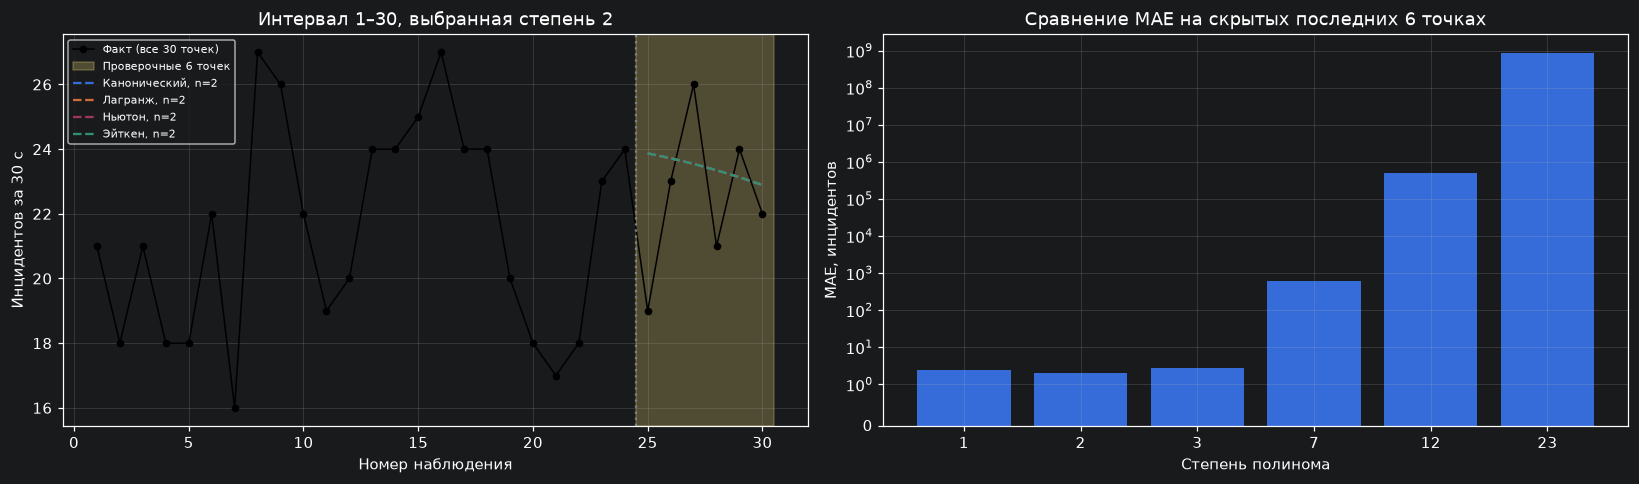

Таблица прогноза для интервала 1–30, степень 2:


,Номер,Факт,Прогноз,Абсолютная ошибка
0,25,19,23.8696,4.8696
1,26,23,23.7174,0.7174
2,27,26,23.5435,2.4565
3,28,21,23.3478,2.3478
4,29,24,23.1304,0.8696
5,30,22,22.8913,0.8913


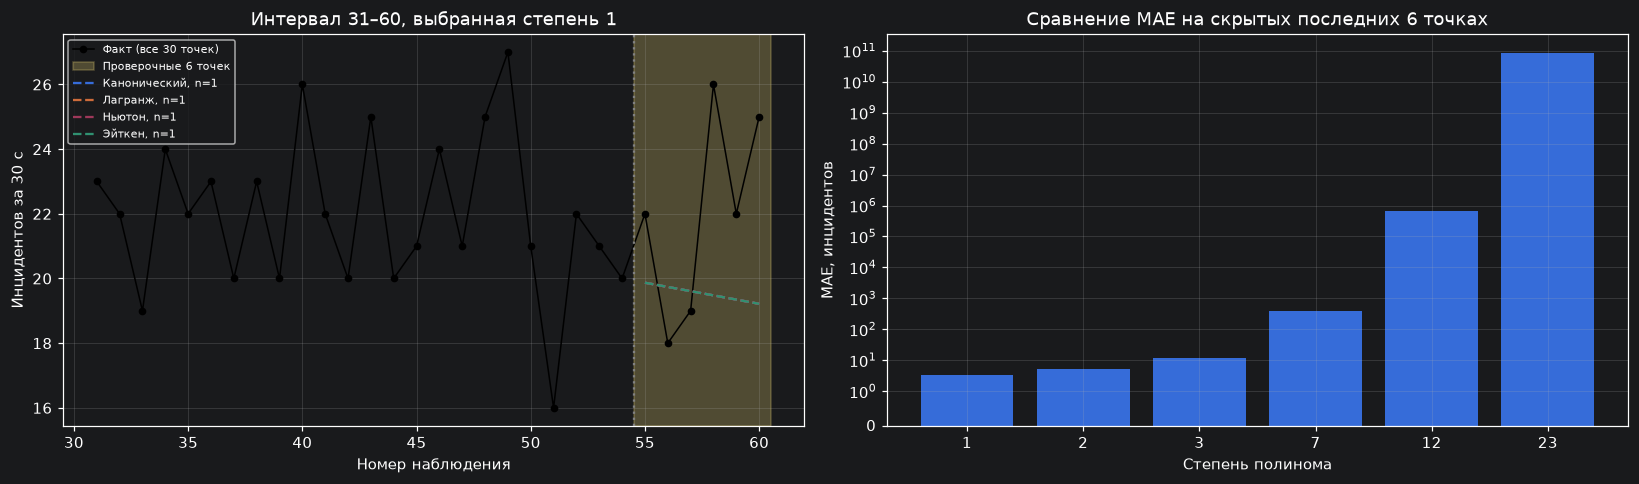

Таблица прогноза для интервала 31–60, степень 1:


,Номер,Факт,Прогноз,Абсолютная ошибка
0,55,22,19.8696,2.1304
1,56,18,19.7391,1.7391
2,57,19,19.6087,0.6087
3,58,26,19.4783,6.5217
4,59,22,19.3478,2.6522
5,60,25,19.2174,5.7826


In [13]:
# Графики настоящего прогноза и фактических проверочных точек
for start,end in INTERVALS:
    label=f'{start}–{end}'; deg=best_degrees[label]
    xx=t[start-1:end]; yy=y[start-1:end]
    xtrain,ytrain=xx[:24],yy[:24]
    xtest,ytest=xx[24:],yy[24:]
    fig,axs=plt.subplots(1,2,figsize=(15,4.5))
    ax=axs[0]
    ax.plot(xx,yy,'ko-',ms=4,lw=1,label='Факт (все 30 точек)')
    ax.axvspan(xtest[0]-.5,xtest[-1]+.5,color='#f6de79',alpha=.25,label='Проверочные 6 точек')
    # 4 метода на одном чертеже: совпадающие линии подтверждают математическую эквивалентность
    for method in METHODS:
        ax.plot(xtest,forecast_store[(label,deg,method)][2],lw=1.5,ls='--',label=f'{method}, n={deg}')
    ax.axvline(xtest[0]-.5,ls=':',c='gray')
    ax.set_title(f'Интервал {label}, выбранная степень {deg}')
    ax.set_xlabel('Номер наблюдения');ax.set_ylabel('Инцидентов за 30 с');ax.legend(fontsize=7)
    ax=axs[1]
    cur=compact[compact['Интервал']==label].sort_values('Степень')
    ax.bar(cur['Степень'].astype(str),cur['MAE'])
    ax.set_title('Сравнение MAE на скрытых последних 6 точках')
    ax.set_xlabel('Степень полинома');ax.set_ylabel('MAE, инцидентов')
    ax.set_yscale('symlog',linthresh=1)
    fig.tight_layout();plt.show()
    print(f'Таблица прогноза для интервала {label}, степень {deg}:')
    display(pd.DataFrame({'Номер':xtest,'Факт':ytest.astype(int),
                          'Прогноз':np.round(forecast_store[(label,deg,'Канонический')][2],4),
                          'Абсолютная ошибка':np.round(abs(ytest-forecast_store[(label,deg,'Канонический')][2]),4)}))

## 5. Понижение степени до выбранной точности

Дополнительно введён **пример** порога `MAPE ≤ 15 %` на проверочных точках. Это **учебный критерий**, не требование методички и не универсальный порог для ИБ. Сравниваются две логики: остановка при **первом** достижении порога (степени перебираются от высокой к низкой) и поиск **минимальной MAE**. Выбор гиперпараметров по проверочным точкам требует отдельного финального теста, если нужна несмещённая оценка качества.

In [14]:
# Пример инженерного критерия «точность стала приемлемой».
# Порог 15% MAPE введён для демонстрации, он НЕ дан в методичке.
MAPE_LIMIT = 15.0
print(f'Демонстрационный порог приемлемости: MAPE <= {MAPE_LIMIT}%')
for label in ['1–30','31–60']:
    part=compact[compact['Интервал']==label].sort_values('Степень',ascending=False)
    eligible=part[part['MAPE, %']<=MAPE_LIMIT]
    if eligible.empty:
        print(f'Интервал {label}: ни одна степень не достигла заданного порога')
    else:
        first=eligible.iloc[0]
        print(f'Интервал {label}: при понижении степени ПЕРВЫМ достиг порога n={int(first["Степень"])} '
              f'(MAPE={first["MAPE, %"]:.2f}%, MAE={first["MAE"]:.3f}).')
        best=part.loc[part['MAE'].idxmin()]
        print(f'  Минимальная MAE на проверке у n={int(best["Степень"])} '
              f'(MAE={best["MAE"]:.3f}, MAPE={best["MAPE, %"]:.2f}%).')
    degree=best_degrees[label]
    start,end=(1,30) if label=='1–30' else (31,60)
    xtr=t[start-1:end][:24]; ytr=y[start-1:end][:24]
    nx,ny,_=make_nodes(xtr,ytr,degree)
    print(f'Коэффициенты рекомендованного по MAE полинома для {label}:')
    print_equation(build_poly(nx,ny),max_terms=None)

Демонстрационный порог приемлемости: MAPE <= 15.0%
Интервал 1–30: при понижении степени ПЕРВЫМ достиг порога n=3 (MAPE=12.57%, MAE=2.823).
  Минимальная MAE на проверке у n=2 (MAE=2.025, MAPE=9.51%).
Коэффициенты рекомендованного по MAE полинома для 1–30:
P(u) = a0 + a1*u + ... + a2*u^2
u = (t - 12.5) / 11.5


,Степень u,Канонический коэффициент a_k,Коэффициент разделенных разностей Ньютона c_k
0,0,23.9375,21.0
1,1,1.5,2.875
2,2,-1.4375,-1.4375


Интервал 31–60: при понижении степени ПЕРВЫМ достиг порога n=1 (MAPE=13.80%, MAE=3.239).
  Минимальная MAE на проверке у n=1 (MAE=3.239, MAPE=13.80%).
Коэффициенты рекомендованного по MAE полинома для 31–60:
P(u) = a0 + a1*u + ... + a1*u^1
u = (t - 42.5) / 11.5


,Степень u,Канонический коэффициент a_k,Коэффициент разделенных разностей Ньютона c_k
0,0,21.5,23.0
1,1,-1.5,-1.5


## 5. Вывод для отчёта

1. По всем 60 точкам строится полином **59-й степени**, а на 30 точках — **29-й степени**. В узлах он воспроизводит фактические данные точно; это не означает высокой точности прогноза.
2. Каноническая, лагранжева, ньютонова и схема Эйткена задают **один и тот же интерполяционный многочлен** для одних и тех же узлов; ошибки при высокой точности должны совпадать.
3. При уменьшении степени с `n+1` выбранными узлами уменьшается гибкость полинома, а ошибки на неиспользованных точках могут как снижаться, так и возрастать; универсального правила «чем ниже, тем точнее» нет.
4. Для интенсивности SSH brute-force, которая заметно колеблется, интерполяция большой степени склонна к сильным осцилляциям и крайне ненадёжной экстраполяции. Степень следует выбирать на отложенных данных, причём обоснование прогностической пригодности нельзя делать только по попаданию в узлы.
5. Для проверки в ноутбуке имеются графики по двум интервалам, полные коэффициенты в нормированной переменной и таблицы MAE/MSE/RMSE/MAPE на проверочных точках.

## 6. Итоговые таблицы: значения полинома по четырём методам и их сравнение

Сводные таблицы в конце работы. Сначала — значения `P(t)`, вычисленные **каждым из четырёх способов** (канонический, Лагранж, Ньютон, Эйткен) в одних и тех же точках: в узлах, между узлами и на обоих интервалах для разных степеней. Затем — прямое сравнение методов между собой: попарные расхождения значений на полной точности `mpmath` и время вычисления одного значения.

Все четыре формы задают математически **один и тот же** многочлен, поэтому в `float64` их значения совпадают до последнего знака (расхождение 0). На полной точности `mpmath` видны чисто вычислительные расхождения порядка 10⁻⁶⁴–10⁻⁹⁰ — на десятки порядков меньше цены младшего разряда `float64` (≈2·10⁻¹⁶). Практическое различие методов проявляется не в значениях, а во **времени вычисления**: схема Эйткена—Невилла имеет квадратичную сложность по числу узлов и при степени 59 работает на два порядка дольше остальных форм.


In [15]:
# === Значения P(t) по четырём методам в одних и тех же точках ===
def poly_values_table(poly, points):
    tbl = pd.DataFrame({m: predict(poly, points, m) for m in METHODS},
                       index=[f'{q:g}' for q in points]); tbl.index.name = 't'
    arr = tbl[METHODS].to_numpy()
    diff = arr.max(axis=1) - arr.min(axis=1)          # расхождение после приведения к float64
    out = pd.DataFrame({m: tbl[m].map(lambda v: f'{v:.6g}') for m in METHODS})
    out['Расхождение методов'] = [f'{d:.1e}' for d in diff]
    return out

print('Полином степени 59 по всем 60 точкам — значения В УЗЛАХ (t = 1..60):')
display(poly_values_table(full, np.arange(1, 61, 1.0)))
print('Полином степени 59 — значения МЕЖДУ УЗЛАМИ (t = 1.5, 2.5, …, 59.5; виден масштаб осцилляций Рунге):')
display(poly_values_table(full, np.arange(1.5, 60.0, 1.0)))
for label in ['1–30', '31–60']:
    s, e = map(int, label.split('–'))
    for deg in [7, 3]:
        p, _ = polys_intervals[(label, deg)]
        print(f'Интервал {label}, степень {deg} — значения P(t) с шагом 0.5:')
        display(poly_values_table(p, np.arange(s, e + 0.5, 0.5)))


Полином степени 59 по всем 60 точкам — значения В УЗЛАХ (t = 1..60):


,Канонический,Лагранж,Ньютон,Эйткен,Расхождение методов
t,,,,,
1,21,21,21,21,0.0e+00
2,18,18,18,18,0.0e+00
3,21,21,21,21,0.0e+00
4,18,18,18,18,0.0e+00
5,18,18,18,18,0.0e+00
6,22,22,22,22,0.0e+00
7,16,16,16,16,0.0e+00
8,27,27,27,27,0.0e+00
9,26,26,26,26,0.0e+00


Полином степени 59 — значения МЕЖДУ УЗЛАМИ (t = 1.5, 2.5, …, 59.5; виден масштаб осцилляций Рунге):


,Канонический,Лагранж,Ньютон,Эйткен,Расхождение методов
t,,,,,
1.5,-1.66301e+13,-1.66301e+13,-1.66301e+13,-1.66301e+13,0.0e+00
2.5,4.87548e+11,4.87548e+11,4.87548e+11,4.87548e+11,0.0e+00
3.5,-2.4182e+10,-2.4182e+10,-2.4182e+10,-2.4182e+10,0.0e+00
4.5,1.70617e+09,1.70617e+09,1.70617e+09,1.70617e+09,0.0e+00
5.5,-1.57404e+08,-1.57404e+08,-1.57404e+08,-1.57404e+08,0.0e+00
6.5,1.80654e+07,1.80654e+07,1.80654e+07,1.80654e+07,0.0e+00
7.5,-2.49615e+06,-2.49615e+06,-2.49615e+06,-2.49615e+06,0.0e+00
8.5,405755,405755,405755,405755,0.0e+00
9.5,-76230.7,-76230.7,-76230.7,-76230.7,0.0e+00


Интервал 1–30, степень 7 — значения P(t) с шагом 0.5:


...

,Канонический,Лагранж,Ньютон,Эйткен,Расхождение методов
t,,,,,
1,21,21,21,21,0.0e+00
1.5,20.9451,20.9451,20.9451,20.9451,0.0e+00
2,20.882,20.882,20.882,20.882,0.0e+00
2.5,20.8113,20.8113,20.8113,20.8113,0.0e+00
3,20.7336,20.7336,20.7336,20.7336,0.0e+00
3.5,20.6493,20.6493,20.6493,20.6493,0.0e+00
4,20.5592,20.5592,20.5592,20.5592,0.0e+00
4.5,20.4638,20.4638,20.4638,20.4638,0.0e+00
5,20.3636,20.3636,20.3636,20.3636,0.0e+00


Интервал 31–60, степень 7 — значения P(t) с шагом 0.5:


,Канонический,Лагранж,Ньютон,Эйткен,Расхождение методов
t,,,,,
31,23,23,23,23,0.0e+00
31.5,25.663,25.663,25.663,25.663,0.0e+00
32,26.874,26.874,26.874,26.874,0.0e+00
32.5,27.0468,27.0468,27.0468,27.0468,0.0e+00
33,26.5191,26.5191,26.5191,26.5191,0.0e+00
33.5,25.5621,25.5621,25.5621,25.5621,0.0e+00
34,24.3886,24.3886,24.3886,24.3886,0.0e+00
34.5,23.1613,23.1613,23.1613,23.1613,0.0e+00
35,22,22,22,22,0.0e+00


Интервал 31–60, степень 3 — значения P(t) с шагом 0.5:


,Канонический,Лагранж,Ньютон,Эйткен,Расхождение методов
t,,,,,
31,23,23,23,23,0.0e+00
31.5,23.0361,23.0361,23.0361,23.0361,0.0e+00
32,23.0588,23.0588,23.0588,23.0588,0.0e+00
32.5,23.0689,23.0689,23.0689,23.0689,0.0e+00
33,23.0672,23.0672,23.0672,23.0672,0.0e+00
33.5,23.0542,23.0542,23.0542,23.0542,0.0e+00
34,23.0307,23.0307,23.0307,23.0307,0.0e+00
34.5,22.9975,22.9975,22.9975,22.9975,0.0e+00
35,22.9552,22.9552,22.9552,22.9552,0.0e+00


In [16]:
# === Сравнение четырёх методов между собой ===
import time

SHORT = {'Канонический': 'Кан', 'Лагранж': 'Лаг', 'Ньютон': 'Нью', 'Эйткен': 'Эйт'}
scenarios = [('1–60 (все точки)', 59, full, 1, 60)]
for label in ['1–30', '31–60']:
    s, e = map(int, label.split('–'))
    for deg in DEGREES_FULL:
        scenarios.append((label, deg, polys_intervals[(label, deg)][0], s, e))

# 1) Попарные расхождения значений на ПОЛНОЙ точности mpmath (в float64 они уже нулевые)
rows = []
for name, deg, p, s, e in scenarios:
    grid = np.linspace(s, e, 181)
    vals = {m: [eval_one(p, float(q), m) for q in grid] for m in METHODS}
    rows.append({'Сценарий': name, 'Степень': deg,
                 **{f'{SHORT[a]}—{SHORT[b]}': mp.nstr(max(abs(vals[a][k] - vals[b][k])
                                                           for k in range(len(grid))), 3)
                    for a, b in combinations(METHODS, 2)}})
print('1) Максимальные попарные расхождения |P_a(t) − P_b(t)| на плотной сетке (mpmath, dps=90):')
display(pd.DataFrame(rows))
print('Обозначения: Кан — канонический, Лаг — Лагранж, Нью — Ньютон, Эйт — Эйткен.')
print('Все расхождения ≪ 10⁻⁶³: четыре формы дают один и тот же многочлен, различия чисто вычислительные.')

# 2) Практическое различие — время вычисления одного значения P(t)
timing_rows = []
for name, deg, p, s, e in scenarios:
    grid = np.linspace(s, e, 61)
    row = {'Сценарий': name, 'Степень': deg}
    for m in METHODS:
        t0 = time.perf_counter(); predict(p, grid, m)
        row[m] = (time.perf_counter() - t0) / len(grid) * 1e3
    timing_rows.append(row)
print('2) Время вычисления одного значения P(t), мс:')
display(pd.DataFrame(timing_rows).round(3))

# 3) Совпадение метрик качества (MAE/RMSE) между методами по итогам разделов 3 и 4
for tbl_name, tbl in [('Восстановление пропущенных точек (раздел 3)', results_reconstruct),
                      ('Прогноз на скрытых 6 точках (раздел 4)', forecast_table)]:
    spread = tbl.groupby(['Интервал', 'Степень'])[['MAE', 'RMSE']].agg(lambda s: float(s.max() - s.min()))
    print(f"3) {tbl_name}: максимальное расхождение метрик между четырьмя методами — "
          f"MAE: {spread['MAE'].max():.2e}, RMSE: {spread['RMSE'].max():.2e}")


1) Максимальные попарные расхождения |P_a(t) − P_b(t)| на плотной сетке (mpmath, dps=90):


,Сценарий,Степень,Кан—Лаг,Кан—Нью,Кан—Эйт,Лаг—Нью,Лаг—Эйт,Нью—Эйт
0,1–60 (все точки),59,5.22e-64,2.78e-64,2.78e-64,8.0e-64,8.0e-64,3.49e-65
1,1–30,29,6.13e-79,4.29e-79,4.29e-79,5.39e-79,1.84e-79,4.72e-79
2,1–30,14,2.32e-86,4.16e-85,2.38e-86,4.18e-85,3.2e-87,4.17e-85
3,1–30,7,3.53e-89,1.3e-88,3.14e-89,1.41e-88,1.57e-89,1.45e-88
4,1–30,3,3.93e-90,3.93e-90,7.85e-90,3.93e-90,1.18e-89,7.85e-90
5,1–30,1,7.85e-90,0.0,3.93e-90,7.85e-90,7.85e-90,3.93e-90
6,31–60,29,1.71e-79,1.2e-78,2.08e-79,1.22e-78,3.66e-80,1.25e-78
7,31–60,14,3.5e-86,4.42e-86,3.55e-86,1.74e-86,1.89e-87,1.72e-86
8,31–60,7,2.36e-89,2.2e-88,2.36e-89,2.2e-88,1.96e-89,2.2e-88
9,31–60,3,7.85e-90,3.93e-90,7.85e-90,7.85e-90,1.18e-89,7.85e-90


Обозначения: Кан — канонический, Лаг — Лагранж, Нью — Ньютон, Эйт — Эйткен.
Все расхождения ≪ 10⁻⁶³: четыре формы дают один и тот же многочлен, различия чисто вычислительные.
2) Время вычисления одного значения P(t), мс:


,Сценарий,Степень,Канонический,Лагранж,Ньютон,Эйткен
0,1–60 (все точки),59,0.076,0.148,0.107,6.870
1,1–30,29,0.040,0.065,0.051,1.645
2,1–30,14,0.023,0.038,0.028,0.404
3,1–30,7,0.014,0.023,0.015,0.110
4,1–30,3,0.010,0.015,0.009,0.027
5,1–30,1,0.007,0.012,0.006,0.008
6,31–60,29,0.042,0.064,0.052,1.649
7,31–60,14,0.024,0.044,0.032,0.426
8,31–60,7,0.015,0.025,0.021,0.121
9,31–60,3,0.011,0.018,0.011,0.026


3) Восстановление пропущенных точек (раздел 3): максимальное расхождение метрик между четырьмя методами — MAE: 0.00e+00, RMSE: 0.00e+00
3) Прогноз на скрытых 6 точках (раздел 4): максимальное расхождение метрик между четырьмя методами — MAE: 0.00e+00, RMSE: 0.00e+00
